# Tuần 3: tinh chỉnh, đóng băng cấu hình, đánh giá cuối trên test

Notebook chỉ **hiển thị kết quả** đã tính (không chạy lại thí nghiệm, không đọc tập test).
Các lựa chọn dựa trên CV trên **train**; tập test được đánh giá **một lần** bởi `src/final_eval.py`.
Báo cáo đầy đủ: `reports/week3_report.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.float_format', '{:,.2f}'.format, 'display.max_colwidth', 80)
T, F = ROOT / 'reports' / 'tables', ROOT / 'reports' / 'figures'
frozen = json.loads((ROOT / 'reports' / 'week3_frozen_config.json').read_text(encoding='utf-8'))
print('Mô hình được chọn bằng CV:', frozen['selected_model'], '| đóng băng lúc', frozen['created_at'])
print('Đánh giá test đã thực hiện:', json.loads((T / 'week3_test_evaluation_done.json').read_text())['evaluated_at'])

Mô hình được chọn bằng CV: rf | đóng băng lúc 2026-11-05T22:56:02
Đánh giá test đã thực hiện: 2026-11-06T20:45:01


## 1. Tinh chỉnh siêu tham số (CV trên train)

In [2]:
tv = pd.read_csv(T / 'week3_tune_vs_default.csv')
tv[['model','n_configs_tried','n_infeasible','default_mae','tuned_mae','gain_pct','folds_tuned_better','tuned_log_target','tuned_params','any_best_mae','any_best_est_full_fit_s']]

,model,n_configs_tried,n_infeasible,default_mae,tuned_mae,gain_pct,folds_tuned_better,tuned_log_target,tuned_params,any_best_mae,any_best_est_full_fit_s
0,knn,22,0,"9,621.97","9,477.84",-1.50,3,True,"{""n_neighbors"": 10, ""p"": 1, ""weights"": ""distance""}","9,477.84",3.01
1,ridge,26,0,"22,681.17","9,499.54",-58.12,5,True,"{""alpha"": 3.1622776601683795}","9,499.54",3.45
2,svr,21,14,"9,445.45","7,976.83",-15.55,5,True,"{""C"": 1.0, ""epsilon"": 0.1, ""gamma"": 0.012}","6,817.73","42,448.17"
3,rf,14,1,"7,369.14","7,351.23",-0.24,2,False,"{""max_depth"": 15, ""max_features"": 0.5, ""min_samples_leaf"": 1, ""n_estimators""...","7,221.43","3,291.85"


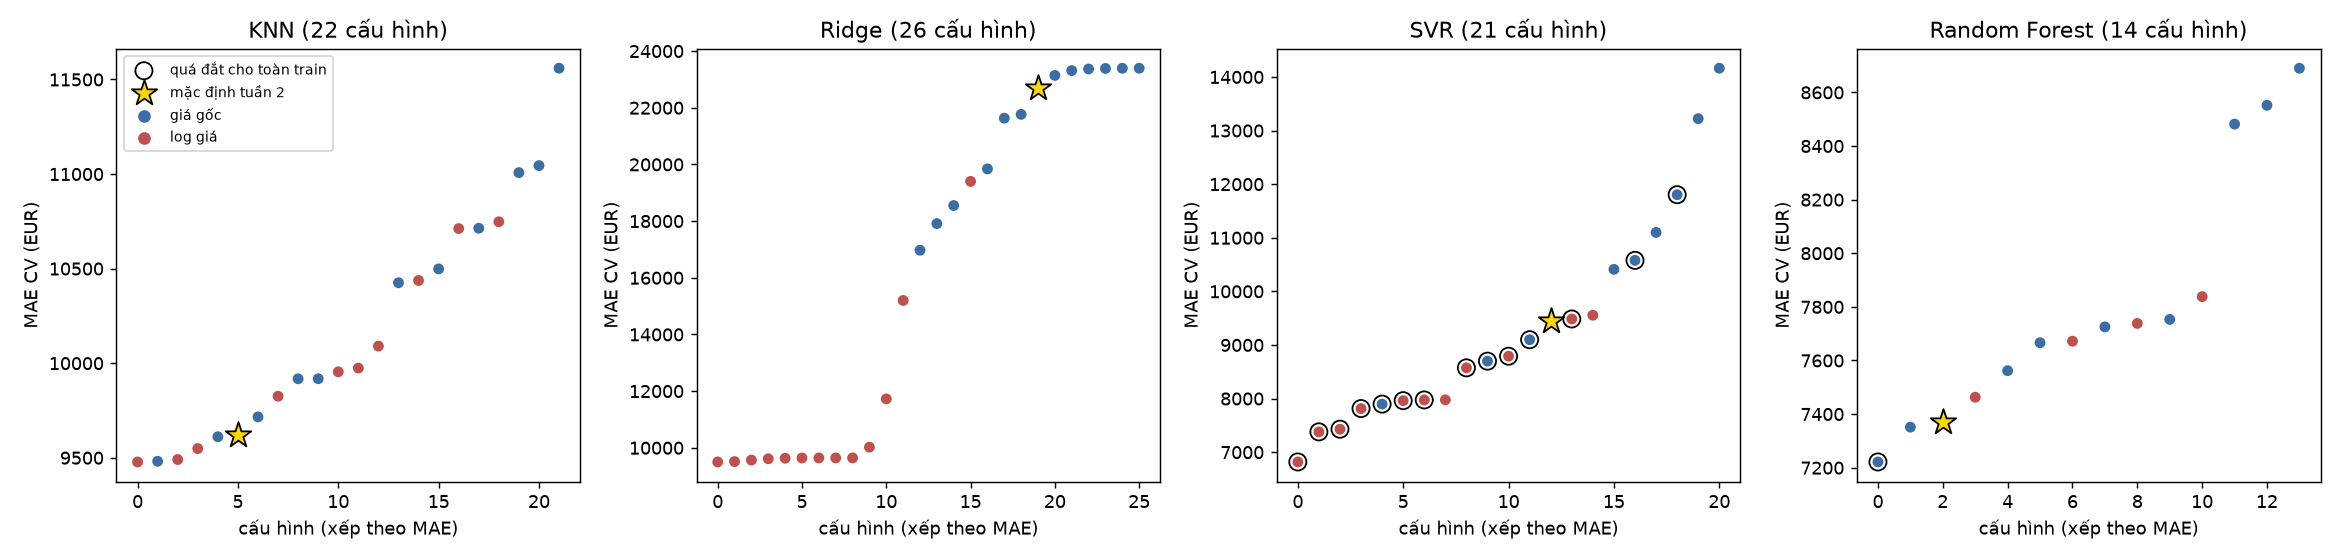

In [3]:
display(Image(str(F / 'week3_tuning.png')))

Vòng tròn đen = cấu hình quá đắt để huấn luyện lại trên toàn train (ước tính > 30 phút), không đủ điều kiện được chọn.

## 2. Cắt xe giá cực cao khỏi tập huấn luyện

,model,extreme_q,mae,mae_lt_100k,mae_ge_100k,bias_ge_100k,rmse,folds_better_than_none,rel_change_pct
0,knn,none,"9,477.84","5,029.42","40,972.66","-30,226.36","69,952.65",NaN,0.00
1,knn,0.999,"9,629.86","5,020.64","42,254.10","-31,864.67","76,514.35",2.00,1.60
2,knn,0.99,"10,043.68","4,965.28","46,005.43","-38,847.00","77,868.20",0.00,5.97
3,ridge,none,"9,499.54","4,799.88","42,737.24","-17,197.01","72,394.18",NaN,0.00
4,ridge,0.999,"9,456.46","4,729.62","42,888.74","-19,407.66","74,439.77",4.00,-0.45
5,ridge,0.99,"9,502.19","4,687.28","43,580.40","-22,296.59","74,961.34",3.00,0.03
6,svr,none,"7,976.83","4,004.44","36,011.43","-25,602.34","66,792.97",NaN,0.00
7,svr,0.999,"8,147.54","4,006.54","37,376.88","-27,583.66","73,654.50",0.00,2.14
8,svr,0.99,"8,330.57","3,982.64","39,034.85","-31,585.71","75,343.49",0.00,4.43
9,rf,none,"7,351.23","4,505.21","27,707.11","-13,123.93","41,839.04",NaN,0.00


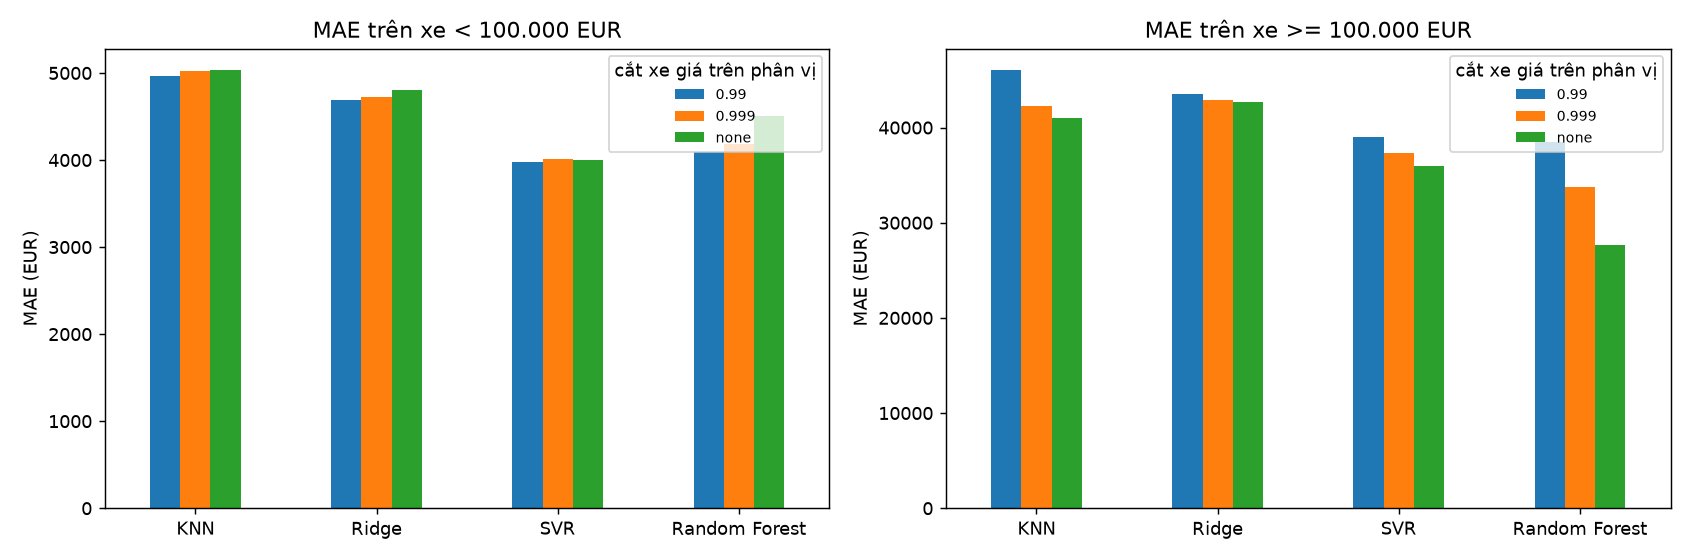

In [4]:
display(pd.read_csv(T / 'week3_extremes_effect.csv'))
display(Image(str(F / 'week3_extremes.png')))

## 3. `model_version` và gom danh mục hiếm

,model,encoder,rare_min_count,mae,baseline_mae,rel_change_pct,n_features_out,folds_better
0,knn,onehot,none,"9,487.07","9,477.84",0.10,314,1
1,knn,onehot,10,"9,487.07","9,477.84",0.10,314,1
2,knn,onehot,50,"9,612.54","9,477.84",1.42,139,0
3,knn,onehot,200,"9,748.78","9,477.84",2.86,87,0
4,knn,target,none,"9,153.89","9,477.84",-3.42,22,5
5,knn,target,10,"9,237.28","9,477.84",-2.54,22,5
6,knn,target,50,"9,496.51","9,477.84",0.20,22,1
7,knn,target,200,"9,715.86","9,477.84",2.51,22,0
8,ridge,onehot,none,"9,483.23","9,499.54",-0.17,314,4
9,ridge,onehot,10,"9,483.24","9,499.54",-0.17,314,4


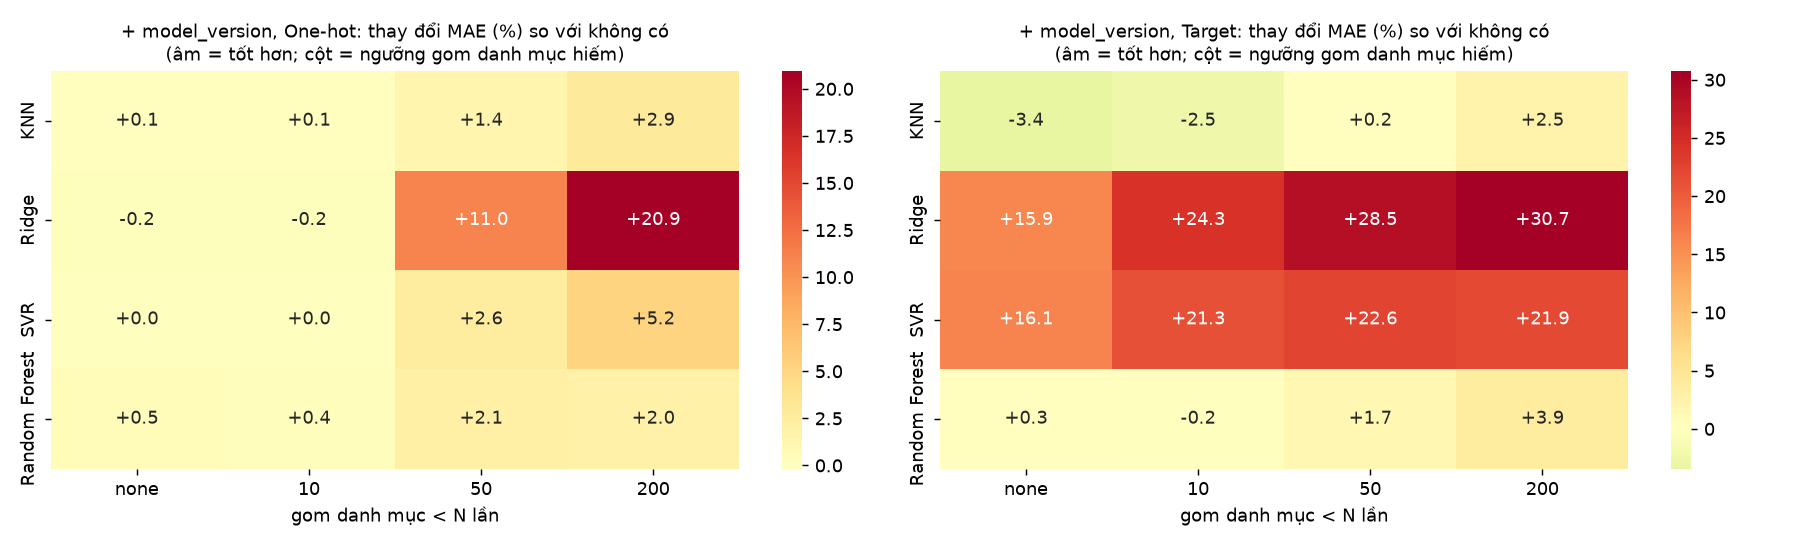

In [5]:
display(pd.read_csv(T / 'week3_grouping_effect.csv'))
display(Image(str(F / 'week3_grouping.png')))

## 4. Cấu hình đóng băng

In [6]:
rows = []
for m, v in frozen['models'].items():
    e = v['final']
    rows.append(dict(model=m, encoder=e['encoder'], scaler=e['scaler'], log_target=e['log_target'], extreme_q=e['extreme_q'], feature_set=e['feature_set'],
                     rare_min_count=e['rare_min_count'], params=e['params'], cv_mae=e['cv']['mae_mean'], default_cv_mae=v['default']['cv']['mae_mean']))
pd.DataFrame(rows)

,model,encoder,scaler,log_target,extreme_q,feature_set,rare_min_count,params,cv_mae,default_cv_mae
0,knn,target,standard,True,NaN,with_model_version,None,"{'n_neighbors': 10, 'p': 1, 'weights': 'distance'}","9,153.89","9,621.97"
1,ridge,onehot,minmax,True,1.00,with_model_version,None,{'alpha': 3.1622776601683795},"9,440.87","22,681.17"
2,svr,onehot,standard,True,NaN,main,None,"{'C': 1.0, 'epsilon': 0.1, 'gamma': 0.012}","7,976.83","9,445.45"
3,rf,onehot,standard,False,NaN,main,None,"{'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators'...","7,351.23","7,369.14"


## 5. Đánh giá cuối trên tập test (một lần)

In [7]:
m = pd.read_csv(T / 'week3_test_metrics.csv').sort_values('mae')
ci = pd.read_csv(T / 'week3_test_bootstrap_ci.csv')
mae_ci = ci[(ci.kind == 'metric') & (ci.metric == 'mae')].set_index('name')[['ci_low', 'ci_high']]
m.merge(mae_ci, left_on='name', right_index=True).rename(columns={'ci_low': 'mae_ci_low', 'ci_high': 'mae_ci_high'})

,name,rmse,mae,r2,medape_pct,fit_seconds,n_train_used,is_selected,is_reference,mae_ci_low,mae_ci_high
7,rf_default,"78,601.25","6,557.12",0.47,7.52,"1,141.65",75457,False,False,"5,666.03","7,804.61"
6,svr_tuned,"78,399.15","6,862.30",0.47,8.01,516.54,75457,False,False,"5,950.82","8,073.93"
8,rf_tuned,"75,391.18","7,060.59",0.51,9.25,385.01,75457,True,False,"6,257.29","8,270.20"
9,svr_cvbest_20k,"78,092.41","7,137.89",0.47,8.17,"1,542.62",20001,False,True,"6,234.27","8,330.99"
10,rf_cvbest_20k,"82,183.93","7,526.30",0.42,8.36,321.03,20001,False,True,"6,493.08","8,858.01"
2,knn_tuned,"79,334.82","7,587.35",0.46,9.01,16.71,75457,False,False,"6,660.97","8,822.14"
1,knn_default,"77,017.89","7,928.04",0.49,9.59,47.03,75457,False,False,"7,033.97","9,160.96"
5,svr_default,"75,838.41","8,123.19",0.50,12.26,"4,623.65",75457,False,False,"7,300.17","9,312.82"
4,ridge_tuned,"91,725.29","8,996.90",0.28,10.00,2.13,75381,False,False,"7,843.72","10,313.78"
3,ridge_default,"86,426.60","15,588.79",0.36,23.94,1.80,75457,False,False,"14,569.05","16,845.93"


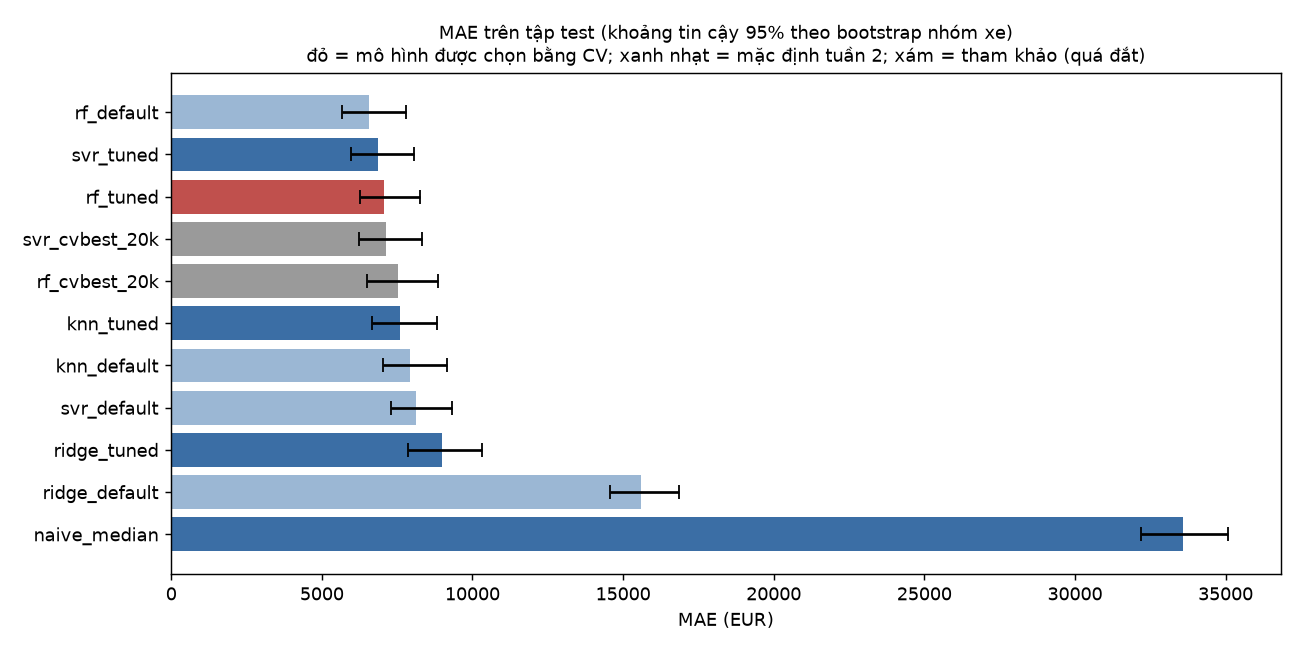

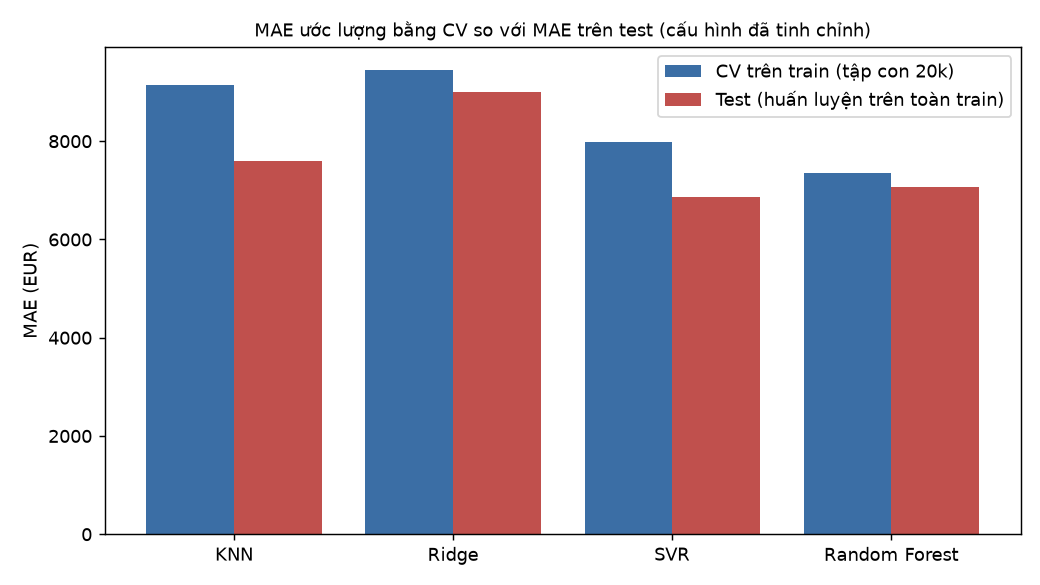

In [8]:
display(Image(str(F / 'week3_test_models.png')))
display(Image(str(F / 'week3_cv_vs_test.png')))

In [9]:
display(ci[ci.kind == 'paired_mae_diff'])

,kind,name,metric,ci_low,ci_high,share_b_better
44,paired_mae_diff,knn_tuned - knn_default,mae,-523.46,-151.56,1.00
45,paired_mae_diff,ridge_tuned - ridge_default,mae,"-7,324.39","-5,883.70",1.00
46,paired_mae_diff,svr_tuned - svr_default,mae,"-1,448.39","-1,057.35",1.00
47,paired_mae_diff,rf_tuned - rf_default,mae,322.58,667.20,0.00
48,paired_mae_diff,rf_tuned - knn_tuned,mae,"-1,043.59",-70.46,0.98
49,paired_mae_diff,rf_tuned - ridge_tuned,mae,"-2,664.65","-1,214.36",1.00
50,paired_mae_diff,rf_tuned - svr_tuned,mae,-267.57,630.77,0.18


## 6. Phân tích phần dư của mô hình được chọn

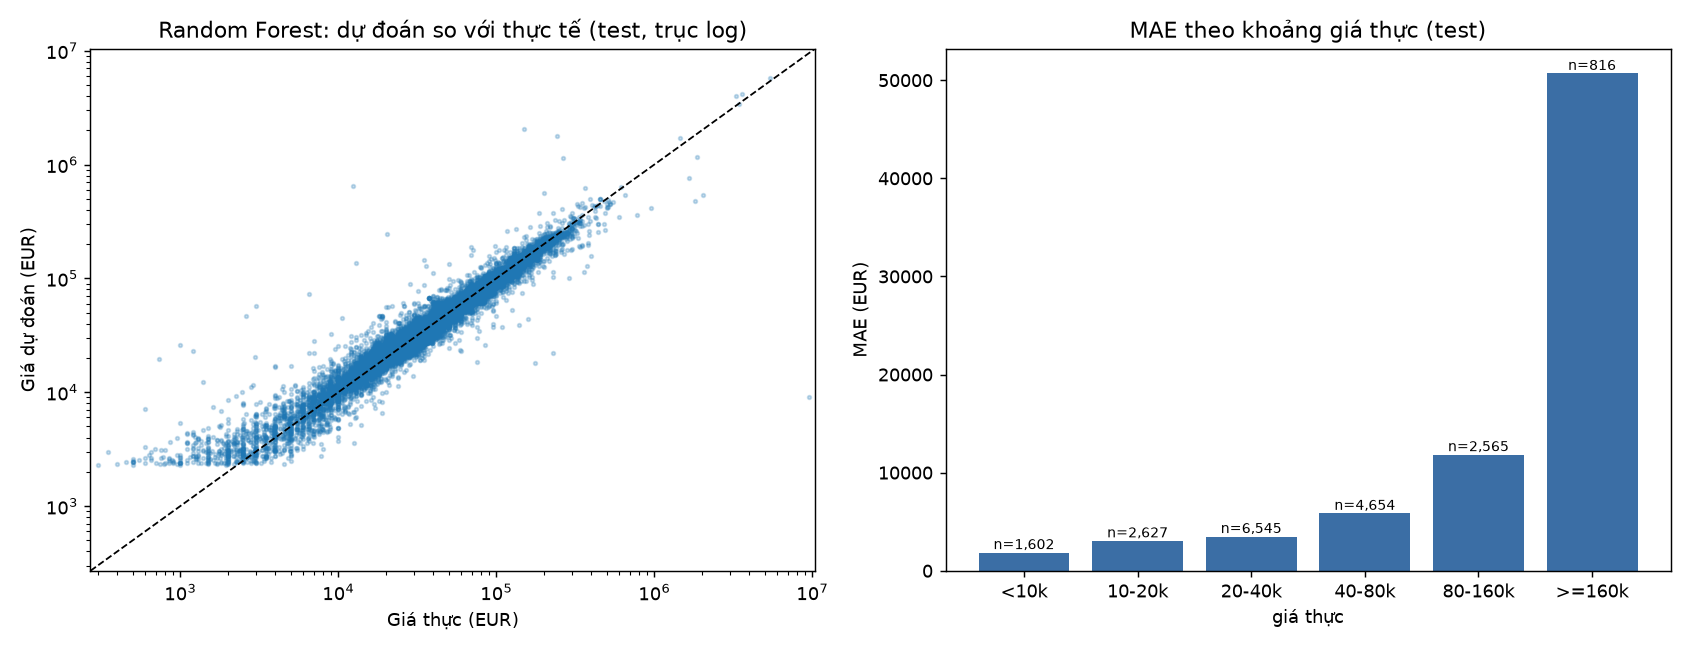

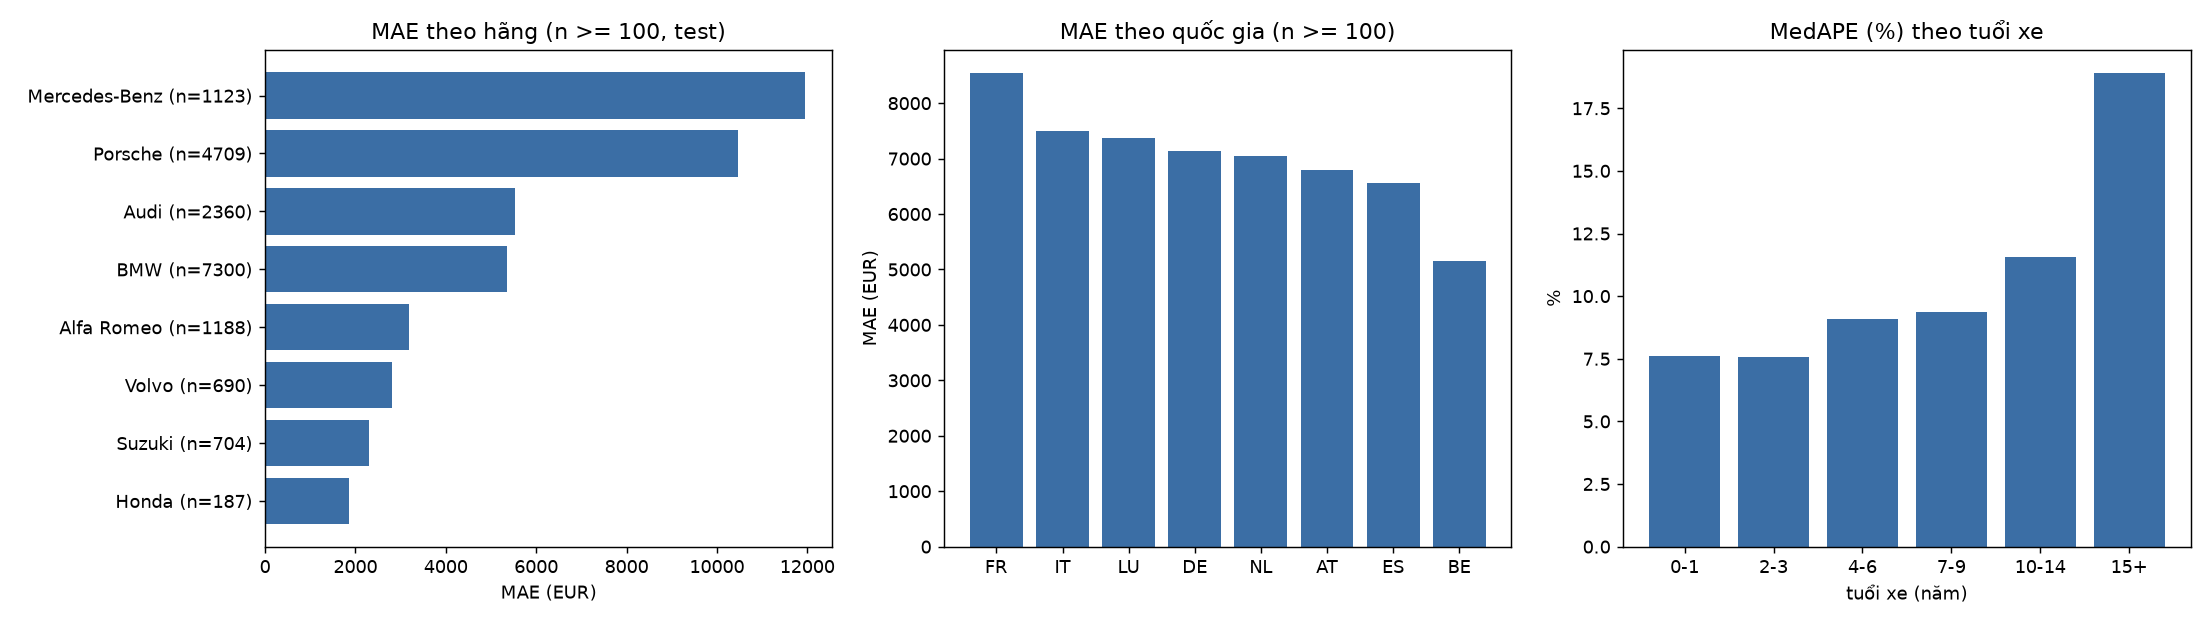

price_band


,key,n,mae,bias,medape_pct,median_price
0,<10k,1602,"1,854.96","1,123.43",24.39,"5,700.00"
1,10-20k,2627,"3,051.82","1,961.01",12.36,"16,900.00"
2,20-40k,6545,"3,490.39",836.47,8.99,"28,900.00"
3,40-80k,4654,"5,852.61",517.35,7.74,"57,950.00"
4,80-160k,2565,"11,839.01",-349.26,7.51,"106,890.00"
5,>=160k,816,"50,691.36","-23,652.56",7.70,"204,754.00"


age_band


,key,n,mae,bias,medape_pct,median_price
0,0-1,3447,"11,276.58",-294.31,7.60,"76,500.00"
1,2-3,2566,"7,515.00",263.21,7.57,"49,407.00"
2,4-6,5806,"5,256.39",32.24,9.09,"31,395.00"
3,7-9,3127,"4,287.66",226.14,9.36,"27,400.00"
4,10-14,2104,"9,148.68","-4,140.70",11.58,"21,495.00"
5,15+,1752,"6,457.64","1,677.07",18.89,"9,000.00"


country


,key,n,mae,bias,medape_pct,median_price
0,FR,1255,"8,535.56",-934.97,8.96,"49,900.00"
1,IT,4203,"7,505.29","-2,125.12",8.62,"31,000.00"
2,LU,133,"7,372.95",954.95,8.20,"63,990.00"
3,DE,6455,"7,128.93","1,875.41",9.45,"34,799.00"
4,NL,2529,"7,043.94","-1,458.02",9.90,"33,940.00"
5,AT,1241,"6,796.08","-3,615.93",9.15,"39,157.00"
6,ES,1331,"6,558.55",-508.44,10.49,"32,600.00"
7,BE,1660,"5,155.18",827.80,8.72,"33,000.00"


brand


,key,n,mae,bias,medape_pct,median_price
0,Mercedes-Benz,1123,"11,954.99","-1,502.57",9.20,"66,945.00"
1,Porsche,4709,"10,461.45",409.33,7.33,"75,500.00"
2,Audi,2360,"5,523.78",358.45,8.09,"39,997.00"
3,BMW,7300,"5,345.09","-1,307.69",10.06,"27,500.00"
4,Alfa Romeo,1188,"3,185.92",540.03,10.47,"24,425.00"
5,Volvo,690,"2,806.12",505.62,13.79,"17,470.00"
6,Suzuki,704,"2,292.99",994.37,11.94,"14,994.00"
7,Honda,187,"1,861.31",-645.10,13.25,"10,995.00"


worst


,brand,model,production_year,mileage_km,country_code,price,pred,err
0,BMW,316,"2,015.00","200,000.00",IT,"9,500,000.00","9,157.90","-9,490,842.10"
1,Porsche,911,"2,006.00","168,950.00",DE,"149,911.00","2,036,130.80","1,886,219.80"
2,Porsche,Taycan,"2,025.00",115.00,DE,"241,800.00","1,764,996.89","1,523,196.89"
3,Porsche,NaN,"2,019.00",53.00,DE,"2,025,000.00","543,669.34","-1,481,330.66"
4,Mercedes-Benz,G 63 AMG,"2,025.00",93.00,DE,"1,814,750.00","479,385.32","-1,335,364.68"
5,Porsche,Carrera GT,"2,004.00","10,504.00",NL,"1,649,950.00","757,349.31","-892,600.69"
6,Porsche,NaN,"2,021.00","21,404.00",NL,"264,950.00","1,147,188.06","882,238.06"
7,Aston Martin,Valkyrie,"2,022.00",769.00,NL,"3,300,000.00","3,995,590.67","695,590.67"
8,Aston Martin,NaN,"2,024.00",55.00,DE,"1,849,007.00","1,173,145.16","-675,861.84"
9,Bugatti,NaN,"1,967.00","60,000.00",NL,"12,345.00","646,013.68","633,668.68"


In [10]:
display(Image(str(F / 'week3_test_pred_vs_actual.png')))
display(Image(str(F / 'week3_test_errors_by_group.png')))
for k in ['price_band', 'age_band', 'country', 'brand', 'worst']:
    print(k); display(pd.read_csv(T / f'week3_test_errors_by_{k}.csv').head(12))

## 7. Kết luận ngắn
- Cấu hình được chốt chỉ từ CV trên train; tập test chỉ dùng một lần (có file đánh dấu và kiểm tra mã băm).
- Số liệu cụ thể và diễn giải: `reports/week3_report.md` (Phụ lục A tự kiểm chứng các phát biểu).
- Hạn chế chính: dữ liệu thiên về xe cao cấp châu Âu; kết luận chưa suy ra được cho thị trường Việt Nam.